# Investigating Glacial and Interglacial Cycles with Python
**GEOG 202 Honors | Guided in-class investigation (~75–90 minutes)**

**Big question:** What is the dominant rythem?

**Learning goals:** (1) read and plot climate data; (2) connect eccentricity, obliquity, and precession to seasonal insolation; (3) interpret CO₂ and benthic δ¹⁸O records; (4) compare ~41-kyr and ~100-kyr variability.

**Instructions:** Run code cells in order with **Shift + Enter**. Code is provided; your job is to experiment and explain. Write answers in the markdown response cells or on the print out. 

**ka** means thousands of years before present.

## Before you begin: data files
This notebook uses the **original datasets referenced by the two course notebooks**.

- `INSOLN.LA2004.BTL.100.csv` — orbital parameters
- `j_65north.csv` — 65°N insolation
- `antarctica2015co2composite.txt` — Antarctic CO₂ composite
- `LR04stack.csv` — LR04 benthic oxygen-isotope stack

**Tip:** If a cell reports `FileNotFoundError`, check the `data` folder before continuing.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

files = ["INSOLN.LA2004.BTL.100.csv", "j_65north.csv", "antarctica2015co2composite.txt", "LR04stack.csv"]
for name in files:
    print(("FOUND  " if (Path("data") / name).exists() else "MISSING"), name)
print("\nAll datasets available:", all((Path("data") / f).exists() for f in files))

FOUND   INSOLN.LA2004.BTL.100.csv
FOUND   j_65north.csv
FOUND   antarctica2015co2composite.txt
FOUND   LR04stack.csv

All datasets available: True


## Part 1 — What is a cycle? (~10 minutes)
A **period** is the time required for one complete repetition. A longer period means fewer cycles over a fixed time span.

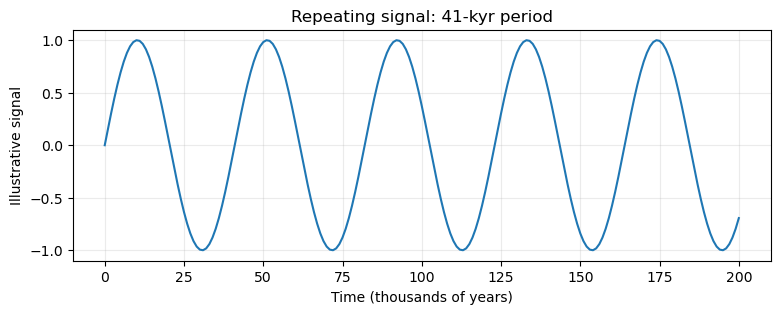

In [12]:
time_ka = np.arange(0, 201)
period_ka = 41  # TRY changing this to 23, 41, or 100
wave = np.sin(2 * np.pi * time_ka / period_ka)
plt.figure(figsize=(9, 3))
plt.plot(time_ka, wave)
plt.xlabel("Time (thousands of years)")
plt.ylabel("Illustrative signal")
plt.title(f"Repeating signal: {period_ka}-kyr period")
plt.grid(alpha=.25)
plt.show()

**Try this:** Run the plot with periods of 23, 41, and 100 kyr. Which completes the most cycles over 200 kyr?

**Your answer:** ...

### A simple introduction to spectral analysis
A **periodogram** shows how strongly different repeating timescales contribute to a signal. The code below uses a synthetic example, not climate observations.

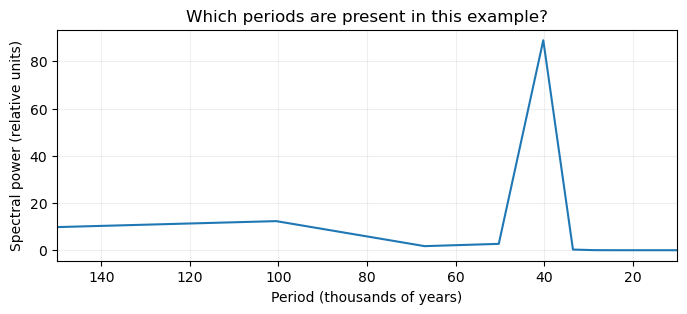

In [13]:
mixed = np.sin(2*np.pi*time_ka/41) + 0.5*np.sin(2*np.pi*time_ka/100)
freq, power = signal.periodogram(mixed, fs=1, detrend="linear")
mask = freq > 0
plt.figure(figsize=(8, 3))
plt.plot(1/freq[mask], power[mask])
plt.xlim(150, 10)
plt.xlabel("Period (thousands of years)")
plt.ylabel("Spectral power (relative units)")
plt.title("Which periods are present in this example?")
plt.grid(alpha=.2)
plt.show()

**Discuss:** Why might a climate record have more than one important period? Spectral peaks indicate recurring variability; by themselves they do **not** prove its cause.

## Part 2 — Milankovitch cycles and insolation (~15 minutes)
The three orbital variations are **eccentricity** (shape of orbit), **obliquity** (axial tilt), and **precession** (orientation of the seasons relative to the orbit). Their characteristic timescales include ~100 kyr, ~41 kyr, and ~19–23 kyr, respectively. These primarily redistribute incoming solar energy by **latitude and season**, rather than producing large changes in global annual-average sunlight.

Columns: ['Age (ka)', 'Eccentricity', 'Obliquity', 'Precession']


,Age (ka),Eccentricity,Obliquity,Precession
0,0,0.016702,0.409093,1.796257
1,1,0.017161,0.411353,1.497928
2,2,0.017497,0.413555,1.200024
3,3,0.017846,0.415639,0.903494
4,4,0.018211,0.417555,0.611381


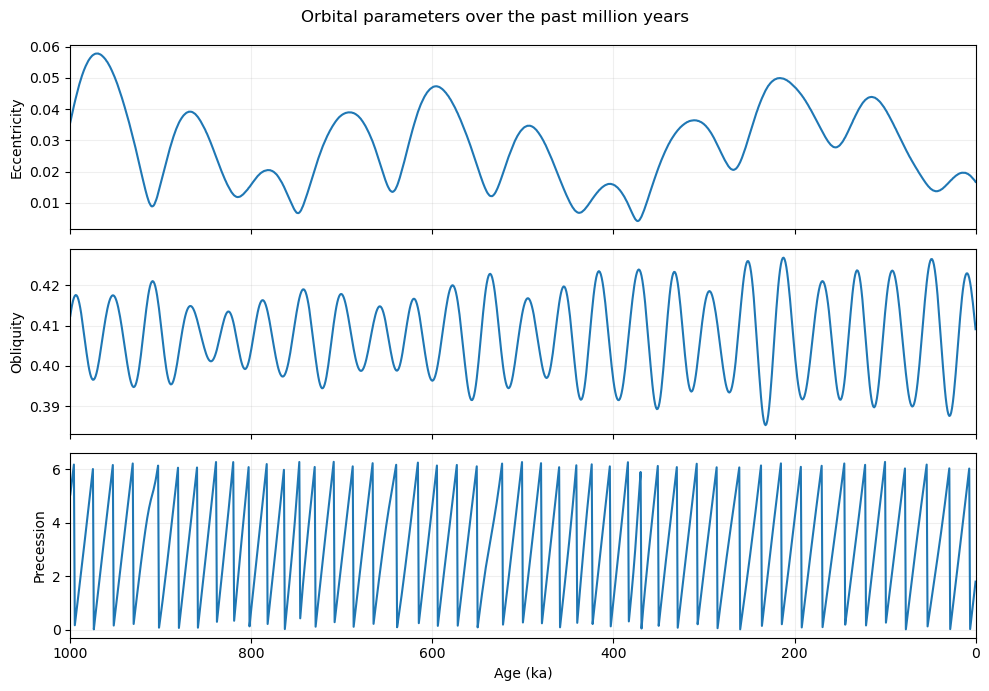

In [14]:
orbital = pd.read_csv("data/INSOLN.LA2004.BTL.100.csv")
print("Columns:", orbital.columns.tolist())
display(orbital.head())
recent_orbital = orbital.loc[orbital["Age (ka)"].between(0, 1000)].sort_values("Age (ka)")
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, col in zip(axes, ["Eccentricity", "Obliquity", "Precession"]):
    ax.plot(recent_orbital["Age (ka)"], recent_orbital[col])
    ax.set_ylabel(col)
    ax.grid(alpha=.2)
axes[-1].set_xlabel("Age (ka)")
axes[-1].set_xlim(1000, 0)
fig.suptitle("Orbital parameters over the past million years")
plt.tight_layout()
plt.show()

**Look closely:** Which parameter appears to vary fastest? Which varies slowest? Are these patterns perfectly regular?

**Your answer:** ...

Columns: ['Age (ka)', 'Insolation (W/m^2)']


,Age (ka),Insolation (W/m^2)
0,0,6.763
1,1,6.776
2,2,6.788
3,3,6.799
4,4,6.810


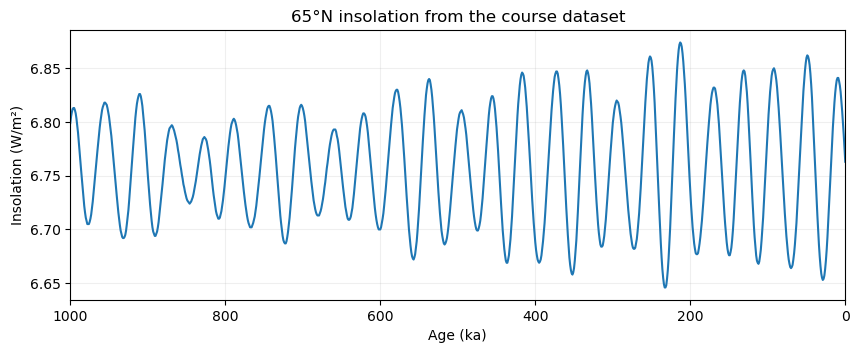

count    1001.0
mean        6.8
std         0.1
min         6.6
25%         6.7
50%         6.8
75%         6.8
max         6.9
Name: Insolation (W/m^2), dtype: float64


In [15]:
insolation = pd.read_csv("data/j_65north.csv")
print("Columns:", insolation.columns.tolist())
display(insolation.head())
insol = insolation.loc[insolation["Age (ka)"].between(0, 1000)].sort_values("Age (ka)")
plt.figure(figsize=(10, 3.5))
plt.plot(insol["Age (ka)"], insol["Insolation (W/m^2)"])
plt.xlim(1000, 0)
plt.xlabel("Age (ka)")
plt.ylabel("Insolation (W/m²)")
plt.title("65°N insolation from the course dataset")
plt.grid(alpha=.2)
plt.show()
print(insol["Insolation (W/m^2)"].describe().round(1))

**Think:** Why might *summer* insolation near 65°N matter for whether winter snow survives to the following year? Check the course dataset’s metadata to determine which seasonal insolation quantity is represented; do not assume it is an annual mean.

**Your answer:** ...

## Part 3 — What do paleoclimate records tell us? (~15 minutes)
Ice cores preserve atmospheric CO₂ information. CO₂ participates in feedbacks and also changes Earth’s radiative balance. Marine microfossils provide a much longer record: benthic **δ¹⁸O** reflects a combination of global ice volume and deep-ocean temperature, **not** temperature alone.

CO₂ columns: ['age_gas_calBP', 'co2_ppm', 'co2_1s_ppm']


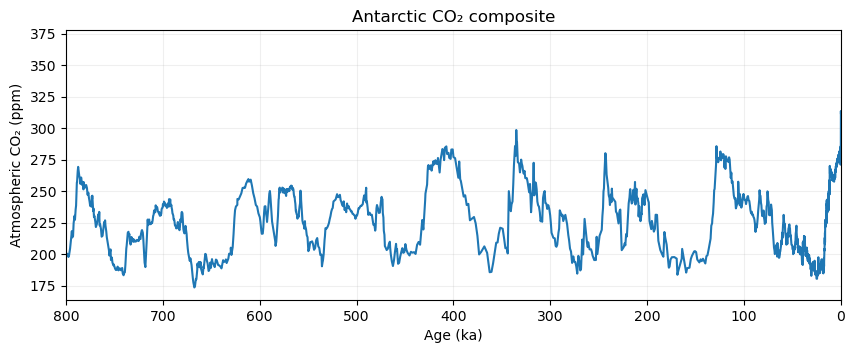

In [16]:
co2 = pd.read_csv("data/antarctica2015co2composite.txt", sep="\t", skiprows=137)
print("CO₂ columns:", co2.columns.tolist())
co2["age_ka"] = co2["age_gas_calBP"] / 1000
co2 = co2.sort_values("age_ka")
plt.figure(figsize=(10, 3.5))
plt.plot(co2["age_ka"], co2["co2_ppm"])
plt.xlim(800, 0)
plt.xlabel("Age (ka)")
plt.ylabel("Atmospheric CO₂ (ppm)")
plt.title("Antarctic CO₂ composite")
plt.grid(alpha=.2)
plt.show()

**Question:** Does CO₂ stay constant through the last several glacial cycles? Why should we avoid claiming that correlation alone proves the direction of causation?

**Your answer:** ...

LR04 columns: ['Age (ka)', 'd18O', 'uncertainty']


,Age (ka),d18O,uncertainty
0,0.0,3.23,0.03
1,1.0,3.23,0.04
2,2.0,3.18,0.03
3,3.0,3.29,0.03
4,4.0,3.30,0.03


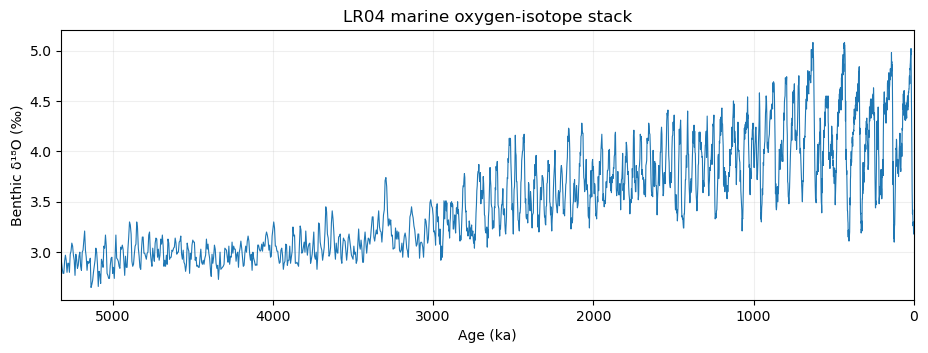

In [17]:
lr04 = pd.read_csv("data/LR04stack.csv")
print("LR04 columns:", lr04.columns.tolist())
display(lr04.head())
lr04 = lr04.sort_values("Age (ka)").dropna(subset=["Age (ka)", "d18O"])
plt.figure(figsize=(11, 3.5))
plt.plot(lr04["Age (ka)"], lr04["d18O"], lw=.8)
plt.xlim(lr04["Age (ka)"].max(), 0)
plt.xlabel("Age (ka)")
plt.ylabel("Benthic δ¹⁸O (‰)")
plt.title("LR04 marine oxygen-isotope stack")
plt.grid(alpha=.2)
plt.show()

**Question:** How far back does the LR04 record extend? Why is a long record useful for investigating whether ice-age rhythms changed?

**Your answer:** ...

## Part 4 — Did the rhythm of ice ages change? (~25 minutes)
The **Mid-Pleistocene Transition (MPT)** was a gradual shift, broadly around 1.2–0.7 million years ago, from stronger ~41-kyr variability toward longer, asymmetric ~100-kyr glacial cycles. The exact timing and mechanisms remain active research topics.

We will compare the four intervals used in the original assignment. The next cell interpolates the irregularly spaced LR04 observations to **1-kyr intervals**. Interpolation helps compare spectra, but does not create new observations.

In [18]:
age = np.arange(np.ceil(lr04["Age (ka)"].min()), np.floor(lr04["Age (ka)"].max())+1, 1)
values = np.interp(age, lr04["Age (ka)"], lr04["d18O"])
regular = pd.DataFrame({"Age (ka)": age, "d18O": values})
print("Regular sampling interval: 1 kyr")
display(regular.head())

Regular sampling interval: 1 kyr


,Age (ka),d18O
0,0.0,3.23
1,1.0,3.23
2,2.0,3.18
3,3.0,3.29
4,4.0,3.30


The following function produces both a time-series plot and a periodogram. **You do not need to memorize this code.** Focus on what the plots show. For a fair comparison, we use the same method for every interval.

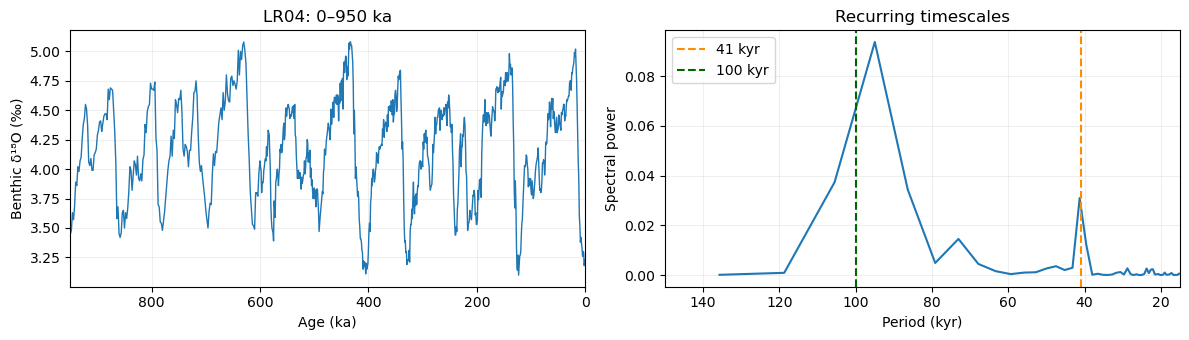

In [19]:
def explore_interval(start_ka, end_ka):
    part = regular.loc[(regular["Age (ka)"] >= start_ka) & (regular["Age (ka)"] < end_ka)]
    if len(part) < 100:
        print("Not enough observations in this interval.")
        return
    f, p = signal.periodogram(part["d18O"].to_numpy(), fs=1.0, window="hann", detrend="linear", scaling="spectrum")
    valid = f > 0  # Exclude zero frequency before converting to period
    periods = 1 / f[valid]
    powers = p[valid]
    band = (periods >= 15) & (periods <= 150)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].plot(part["Age (ka)"], part["d18O"], lw=1)
    axes[0].set_xlim(end_ka, start_ka)
    axes[0].set_xlabel("Age (ka)")
    axes[0].set_ylabel("Benthic δ¹⁸O (‰)")
    axes[0].set_title(f"LR04: {start_ka}–{end_ka} ka")
    axes[1].plot(periods[band], powers[band])
    axes[1].axvline(41, ls="--", color="darkorange", label="41 kyr")
    axes[1].axvline(100, ls="--", color="darkgreen", label="100 kyr")
    axes[1].set_xlim(150, 15)
    axes[1].set_xlabel("Period (kyr)")
    axes[1].set_ylabel("Spectral power")
    axes[1].set_title("Recurring timescales")
    axes[1].legend()
    for ax in axes: ax.grid(alpha=.2)
    plt.tight_layout()
    plt.show()

explore_interval(0, 950)

**Try it:** Change the last line above to run `explore_interval(950, 1900)`, then `explore_interval(1900, 2850)`, and finally `explore_interval(2850, 5320)` (if your data cover that interval).

**Record your observations:**

| Age interval | Stronger variability near 41 kyr or 100 kyr? | What do you notice in the time series? |
|---|---|---|
| 0–950 ka | | |
| 950–1900 ka | | |
| 1900–2850 ka | | |
| 2850–5320 ka | | |

*Note:* Spectral estimates depend on window length, interpolation, and nonstationarity. Peaks need not land exactly at 41 or 100 kyr.

## Part 5 — Putting the evidence together (~10 minutes)
**Discuss with a partner, then answer in your own words:**

1. What changed about glacial–interglacial variability across the MPT? Cite evidence from at least two intervals.
2. Which orbital timescale is closest to the dominant rhythm of the older cycles? Which is closest to the later cycles?
3. Why is it **not** enough to say “eccentricity caused the 100-kyr ice ages”? Consider ice sheets, CO₂, ocean circulation, and other feedbacks.
4. What is one limitation of using a periodogram to explain past climate?

**Your answers:** ...

## Exit ticket
Complete these sentences before you leave:

- One thing I learned about **Python** is ...
- One thing I learned about **glacial cycles** is ...
- One question I still have is ...

**Submission:** Follow your instructor’s directions. This notebook is designed to be completed entirely in class.

**Data and attribution:** Course datasets inherited from the original in-class and assignment notebooks. LR04: Lisiecki & Raymo (2005), *Paleoceanography*, doi:10.1029/2004PA001071. Verify full attribution and units from the original data documentation before redistribution.